# 01 – Data exploration and CSP + LDA baseline

Euclidean baseline for 4-class motor imagery on BCI Competition IV 2a.

- Data pipeline and design choices: `src/riemannian_eeg/data.py` and `docs/design_decisions.md`.
- Why each trial is represented by a covariance (SPD) matrix: `docs/eeg_2_spd.md`.
- Full theory, derivations and references for CSP + LDA: `docs/csp_lda_theory.md`.

In [29]:
from riemannian_eeg.data import load_train_test

X_train, y_train, X_test, y_test = load_train_test(subject=1)
print(X_train.shape, X_test.shape)

(288, 22, 1001) (288, 22, 1001)


## CSP + LDA baseline

CSP (Common Spatial Patterns) + LDA (Linear Discriminant Analysis) is the classic pipeline for
motor imagery, so it's our reference point. It uses the same covariances as the Riemannian methods
but treats them as if they lived in a flat, Euclidean space, so any accuracy gap with MDM (Minimum
Distance to Mean), tangent space or SPDNet comes from the geometry. In short (full derivations in
`docs/csp_lda_theory.md`):

- **CSP** looks for spatial filters $w$ ("virtual electrodes") whose power is large for one class and
  small for another. Since the power of a virtual electrode is $w^\top C\, w$, this means maximizing
  $J(w) = \frac{w^\top C_1 w}{w^\top C_2 w}$, which leads to the generalized eigenvalue problem
  $C_1 w = \lambda C_2 w$, where each eigenvalue is the power ratio of its filter.
- Each trial is then summarized by the log-power of its $k$ filtered signals,
  $f_j = \log(w_j^\top C\, w_j)$: a vector of $k$ roughly Gaussian features.
- **LDA** models each class as a Gaussian cloud with its own centre and a shared shape, and assigns
  each trial to the closest class centre, which gives straight (linear) boundaries between classes.
- **Where it is Euclidean:** CSP builds its filters from the ordinary (arithmetic) mean of each
  class's covariances, ignoring that SPD matrices live in a curved space and that power is compared
  in relative terms. The Riemannian methods replace this with distances based on power ratios and
  the Fréchet mean.

### Physiological intuition

Imagining a movement lowers the mu/beta power over the corresponding motor area (ERD, Event-Related
Desynchronization) and can increase it elsewhere (ERS, Event-Related Synchronization):

| Imagined movement | Motor area involved | Where the power drops (ERD) |
|---|---|---|
| Left hand | Hand area, right hemisphere | Around C4 |
| Right hand | Hand area, left hemisphere | Around C3 |
| Feet | Foot area, on the midline | Around Cz, weaker because the area lies deep |
| Tongue | Face/tongue area, lateral and lower | Less focal; often ERS over the hand areas (C3, C4) |

CSP is never told this, but its filters should end up weighting these electrodes, which we check
later with the spatial patterns.

### The two pipelines

CSP is defined for two classes, so with four classes we compare the two standard extensions:

- **One-vs-Rest (OvR):** four binary CSP + LDA models, one per class against the rest, each with the
  recommended $k = 6$ filters (three pairs; Blankertz et al., 2008).
- **Multiclass CSP:** a single set of filters for all classes, obtained by approximate joint
  diagonalization (Pham's algorithm in MNE) and ranked by mutual information with the class, followed
  by one 4-class LDA. There is no standard value for $k$ here, so we try two to four filters per class,
  $k \in \{8, 12, 16\}$, centred on the reference of three per class.

In [30]:
import mne
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline

mne.set_log_level("WARNING")


def make_ovr():
    """One-vs-Rest: one binary CSP (k=6) + LDA per class."""
    return OneVsRestClassifier(
        make_pipeline(CSP(n_components=6, log=True), LinearDiscriminantAnalysis())
    )


def make_multiclass(k):
    """Multiclass CSP (joint diagonalization, k filters) + 4-class LDA."""
    return make_pipeline(CSP(n_components=k, log=True), LinearDiscriminantAnalysis())

### Choosing the variant by cross-validation

We compare One-vs-Rest ($k = 6$) and multiclass CSP with $k \in \{8, 12, 16\}$ using 5-fold
cross-validation on the training session of each of the 9 subjects: the 288 training trials are
split into 5 parts, each model is trained on 4 and evaluated on the remaining one, and this is
repeated 5 times. The folds are stratified (each one keeps the 4 classes balanced) and fixed with a
random seed, so all candidates are evaluated on exactly the same splits. We then keep the
configuration with the highest mean accuracy across subjects. The test session is never used here.

In [31]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score

SUBJECTS = range(1, 10)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {"OvR (k=6)": make_ovr}
for k in (8, 12, 16):
    candidates[f"Multiclass (k={k})"] = lambda k=k: make_multiclass(k)

rows = []
for subject in SUBJECTS:
    X_tr, y_tr, _, _ = load_train_test(subject)
    for name, make_model in candidates.items():
        scores = cross_val_score(make_model(), X_tr, y_tr, cv=cv)
        rows.append({"subject": subject, "model": name, "cv_accuracy": scores.mean()})

cv_results = pd.DataFrame(rows).pivot(index="subject", columns="model", values="cv_accuracy")
cv_results.loc["mean"] = cv_results.mean()
cv_results.round(3)

model,Multiclass (k=12),Multiclass (k=16),Multiclass (k=8),OvR (k=6)
subject,,,,
1,0.792,0.740,0.743,0.781
2,0.580,0.601,0.621,0.629
3,0.844,0.847,0.840,0.844
4,0.555,0.552,0.531,0.538
5,0.344,0.372,0.375,0.385
6,0.469,0.472,0.486,0.493
7,0.820,0.809,0.799,0.760
8,0.813,0.837,0.813,0.757
9,0.656,0.646,0.653,0.674


All four configurations end up with practically the same mean cross-validation accuracy, between
65.1 % and 65.3 %. A difference of 0.2 points is far smaller than the variation across folds and
subjects, so cross-validation doesn't single out a better variant. Since the numbers can't decide,
we keep the configuration we had justified a priori: multiclass CSP with $k = 12$, three filters per
class, which also gives a single shared set of filters that is easier to interpret than four
separate models.

The more striking thing is how much the subjects differ. Subjects 1, 3, 7 and 8 reach around 75-85 %
with any configuration, subjects 2, 4, 6 and 9 sit in the 50-65 % range, and subject 5 stays around
35-38 %, not far above the 29.5 % chance threshold for 288 trials. This fits the well-known
variability of motor imagery BCIs: some people show a clear ERD and others barely any, whatever the
classifier. Interestingly, One-vs-Rest does slightly better on the weaker subjects (2, 5, 6 and 9)
and multiclass CSP on the strongest ones (7 and 8), as if filters tailored to each class helped when
the signal is weak, but the differences are small, so we take it as an observation rather than a
conclusion.

### CSP spatial patterns of the chosen model (subject 1)

We fit the chosen model (multiclass CSP with $k = 12$ + LDA) on the training session of subject 1 and
plot the spatial pattern of each of its 12 filters. A pattern shows where on the scalp the activity
captured by that virtual electrode lies, so we can check whether CSP focuses on the motor areas
predicted by the physiology, i.e. whether the filters capture brain activity and not noise.

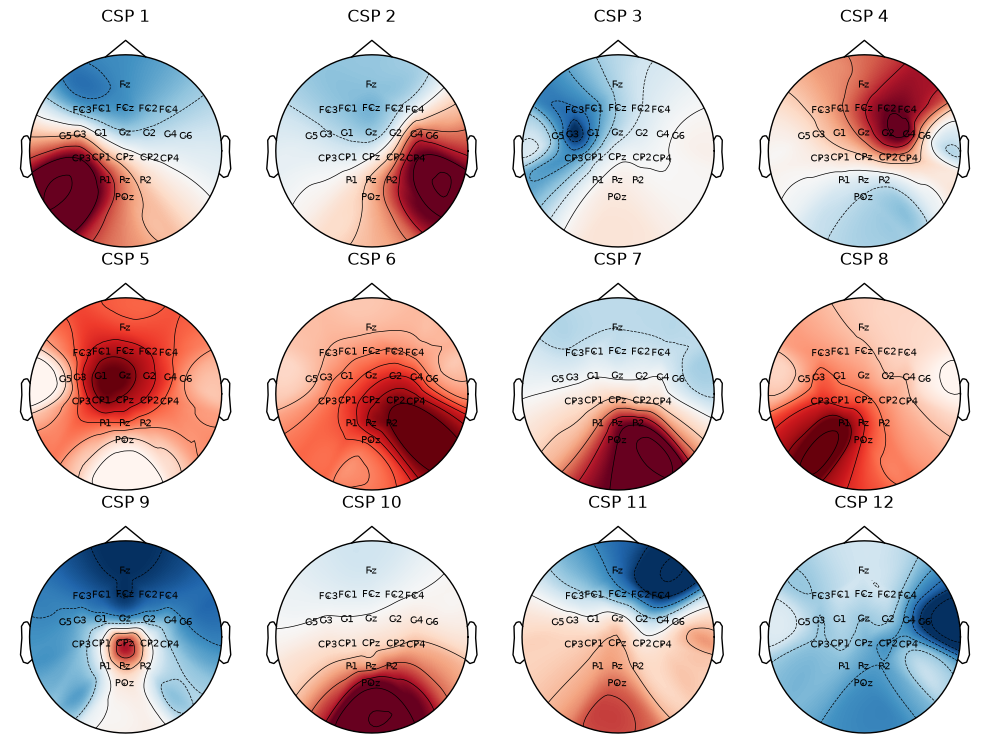

In [32]:
K = 12  # chosen number of filters (multiclass CSP)

import matplotlib.pyplot as plt
import numpy as np

from riemannian_eeg.data import DATASET, PARADIGM

model = make_multiclass(K)
model.fit(X_train, y_train)
csp = model[0]  # first step of the pipeline: the fitted CSP

# MNE epochs object, only needed for the electrode positions
epochs, _, _ = PARADIGM.get_data(dataset=DATASET, subjects=[1], return_epochs=True)

fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for i, ax in enumerate(axes.flat):
    mne.viz.plot_topomap(csp.patterns_[i], epochs.info, axes=ax, show=False,
                         names=epochs.info.ch_names)
    ax.set_title(f"CSP {i + 1}")
plt.tight_layout()
plt.show()

In [33]:
for i in range(K):
    top = np.argsort(np.abs(csp.patterns_[i]))[::-1][:3]
    print(f"CSP {i + 1}:", [epochs.info.ch_names[c] for c in top])

CSP 1: ['CP3', 'P1', 'Fz']
CSP 2: ['CP4', 'C6', 'P2']
CSP 3: ['C3', 'FC3', 'C1']
CSP 4: ['C2', 'FC2', 'C4']
CSP 5: ['C1', 'Cz', 'CP1']
CSP 6: ['P2', 'CP2', 'CP4']
CSP 7: ['POz', 'P2', 'Pz']
CSP 8: ['P1', 'Pz', 'CP3']
CSP 9: ['Fz', 'FCz', 'FC1']
CSP 10: ['POz', 'P2', 'Pz']
CSP 11: ['FC4', 'FC2', 'Fz']
CSP 12: ['C6', 'C4', 'POz']


The patterns line up nicely with the physiology. Listing the three electrodes with the largest
weight in each component, the most informative ones sit right over the sensorimotor areas: CSP 3 is
centred on C3/FC3/C1 and CSP 4 on C2/FC2/C4, the left and right hand regions, and CSP 1 and CSP 2
form a similar left/right pair a bit further back (CP3 vs CP4), where the mu rhythm is usually
strongest. CSP 5 is centred on Cz, where the feet area is. So CSP has found the left-right contrast
that separates the two hands and the midline that points to the feet, even though it only saw the
trials and their labels.

The later, less informative components are more mixed. CSP 9 sits on the frontocentral midline
(Fz/FCz), over the supplementary motor area, which is involved in planning movements and is often
active during motor imagery too, and CSP 12 lies on the lateral right side (C6/C4), the part of the
motor cortex closest to the face and tongue area, so it might be related to the tongue class. No
earlier component stands out for the tongue, which fits with its ERD being less focal. Not every
component is "motor" though: CSP 7 and CSP 10 are mostly posterior (POz/Pz), which might be picking
up visual alpha or noise rather than imagery. Keep in mind that the colour sign doesn't mean
anything here (a filter and its negative are equivalent), only where the pattern is concentrated,
and that the edges of each map are extrapolated since we only have 22 central electrodes.

### Final evaluation on the test session (all subjects)

For each subject, we train the chosen model (multiclass CSP with $k = 12$ + LDA) on the whole
training session and evaluate it once on the test session, recorded on a different day. 
We report accuracy and Cohen's kappa (0 = chance, 1 = perfect), the metric of the original
competition. Since the test classes are balanced, kappa reduces to
$\kappa = (\text{accuracy} - 0.25) / 0.75$. With 288 test trials, an
accuracy above 29.5 % is better than chance with 95 % confidence. Results are saved to
`results/csp_lda.csv`, in the common format shared by all methods.

In [34]:
from riemannian_eeg.data import DATA_DIR
from sklearn.metrics import accuracy_score, cohen_kappa_score

RESULTS_DIR = DATA_DIR.parent / "results"
RESULTS_DIR.mkdir(exist_ok=True)
CHANCE_THRESHOLD = 85 / 288  # 95 % binomial threshold for 288 trials and 4 classes

rows = []
for subject in SUBJECTS:
    X_tr, y_tr, X_te, y_te = load_train_test(subject)
    model = make_multiclass(K).fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    rows.append({"subject": subject,
                 "accuracy": accuracy_score(y_te, y_pred),
                 "kappa": cohen_kappa_score(y_te, y_pred)})

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "csp_lda.csv", index=False)

results["above_chance"] = results["accuracy"] > CHANCE_THRESHOLD
display(results.round(3))
print(f"Mean accuracy: {results['accuracy'].mean():.3f}   Mean kappa: {results['kappa'].mean():.3f}")

,subject,accuracy,kappa,above_chance
0,1,0.778,0.704,True
1,2,0.545,0.394,True
2,3,0.788,0.718,True
3,4,0.611,0.481,True
4,5,0.351,0.134,True
5,6,0.510,0.347,True
6,7,0.615,0.486,True
7,8,0.767,0.690,True
8,9,0.684,0.579,True


Mean accuracy: 0.628   Mean kappa: 0.504


The final model reaches a mean test accuracy of 62.8 % (mean kappa 0.50), and all nine subjects are
above the 29.5 % chance threshold, although subject 5 only barely, at 35.1 %. The spread across
subjects is the same as in cross-validation: subjects 1, 3 and 8 are around 77-79 %, most of the
others between 51 and 68 %, and subject 5 is clearly the hardest one.

Comparing with cross-validation is more interesting. On average the drop from one day to the next is
small (65.2 % to 62.8 %), but it hides very different behaviours: subject 7 falls from 82 % to 61.5 %,
so its model works very well within the same day but doesn't transfer to the next one, while subjects
4 and 6 do slightly better on the test session. This session-to-session shift is exactly what the
cross-session protocol is meant to capture, and where the Riemannian methods are expected to be more
robust, so subject 7 is a good case to watch when comparing methods. For reference, the winning method of the competition on this dataset, FBCSP (which uses several
frequency bands), reported a mean kappa of 0.569 (Ang et al., 2012), so a single-band CSP + LDA at
0.50 is a reasonable baseline, keeping in mind that the competition computed kappa in a slightly
different way (continuous classification within each trial rather than one prediction per trial).

- Ang, K. K., Chin, Z. Y., Wang, C., Guan, C., Zhang, H. (2012). Filter bank common spatial pattern algorithm on BCI Competition IV Datasets 2a and 2b. *Frontiers in Neuroscience*, 6:39.

### How CSP + LDA separates the classes

To see what the model does, we project the trials of subject 1 onto the two main discriminant axes
of LDA, the directions in CSP feature space that best separate the four classes, for the training
and the test session. We also look at which classes get confused, with the confusion matrix of the
test predictions pooled over all subjects.

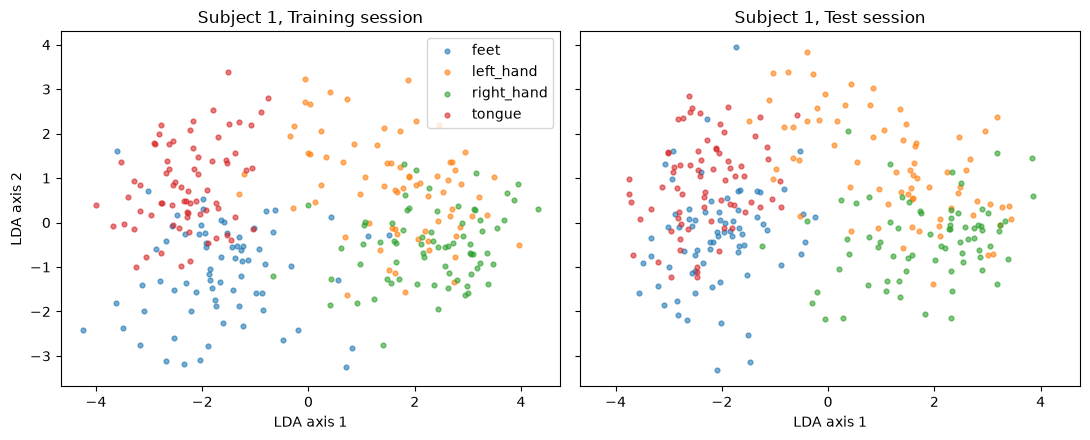

In [35]:
model = make_multiclass(K).fit(X_train, y_train)
csp, lda = model[0], model[1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, X, y, title in zip(axes, (X_train, X_test), (y_train, y_test), ("Training session", "Test session")):
    z = lda.transform(csp.transform(X))  # CSP features -> LDA discriminant axes
    for cls in lda.classes_:
        ax.scatter(z[y == cls, 0], z[y == cls, 1], s=12, alpha=0.6, label=cls)
    ax.set_title(f"Subject 1, {title}")
    ax.set_xlabel("LDA axis 1")
axes[0].set_ylabel("LDA axis 2")
axes[0].legend()
plt.tight_layout()
plt.show()

The LDA space shows quite clearly how the classes are organized. The first axis separates the hands
(left and right hand, on the positive side) from feet and tongue (on the negative side). This is the
main contrast the model finds, and it matches the physiology: both hands produce a lateral ERD over
C3 or C4, while feet and tongue don't, or even increase the power over the hand areas. The second
axis then separates within each group, left hand above right hand and tongue above feet, but these
pairs overlap much more.

On the test session the same structure is still there, so what the model learned on the first day
does carry over, but the clouds are more spread out and overlap more, especially left vs right hand
and feet vs tongue. That is the session-to-session shift showing up directly in feature space, and
it explains why accuracy drops from cross-validation to the test session.

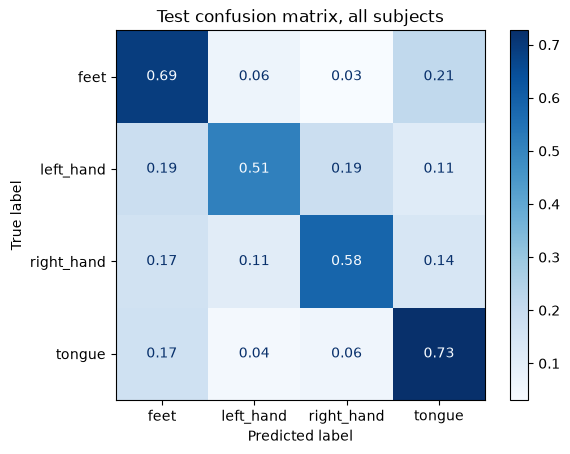

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

y_true_all, y_pred_all = [], []
for subject in SUBJECTS:
    X_tr, y_tr, X_te, y_te = load_train_test(subject)
    y_true_all.extend(y_te)
    y_pred_all.extend(make_multiclass(K).fit(X_tr, y_tr).predict(X_te))

ConfusionMatrixDisplay.from_predictions(y_true_all, y_pred_all, normalize="true",values_format=".2f", cmap="Blues")
plt.title("Test confusion matrix, all subjects")
plt.show()

The confusion matrix, pooled over all subjects, confirms the two pairs seen in the LDA space: feet
and tongue get confused with each other (21 % of feet trials are predicted as tongue and 17 % the
other way round), and so do the two hands (19 % of left-hand trials go to right hand). What is
more surprising is that feet (69 %) and tongue (73 %) are actually the best recognized classes,
while the hands do worse (58 % right, 51 % left) and are often mistaken for feet as well (17-19 %).
This doesn't match subject 1, where the hands were well separated, so it probably comes from the
other subjects: if their hand ERD is weak or not clearly lateralized, the C3/C4 contrast that tells
the hands apart is lost, and those trials end up looking like the non-lateral feet pattern. It's a
plausible explanation rather than something we've tested, but it suggests that separating left from
right hand is the hardest part of the problem for this baseline.